In [1]:
import cv2
from PIL import Image
from pathlib import Path
from torchvision import transforms

# Input and output directories
input_dir = Path("Mini Project/Raw")
output_dir = Path("Mini Project/Processed")

output_dir.mkdir(parents=True, exist_ok=True)

# Define the augmentation pipeline only once
train_augmentation = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.03
    ),
    transforms.ToTensor()
])

# Process 10 original images
for i in range(1, 11):

    image_path = input_dir / f"image {i}.jpg"

    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        print(f"Skipping missing/unreadable image: {image_path}")
        continue

    # OpenCV BGR → RGB → PIL
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_pil = Image.fromarray(image_rgb)

    # Generate 10 augmented versions
    for j in range(1, 11):

        augmented_tensor = train_augmentation(image_pil)

        # Tensor → PIL image
        augmented_image = transforms.ToPILImage()(augmented_tensor)

        # Save each version with a unique filename
        save_path = output_dir / f"image_{i}_aug_{j}.jpg"
        augmented_image.save(save_path)

    print(f"Processed image {i}/10")

Processed image 1/10
Processed image 2/10
Processed image 3/10
Processed image 4/10
Processed image 5/10
Processed image 6/10
Processed image 7/10
Processed image 8/10
Processed image 9/10
Processed image 10/10


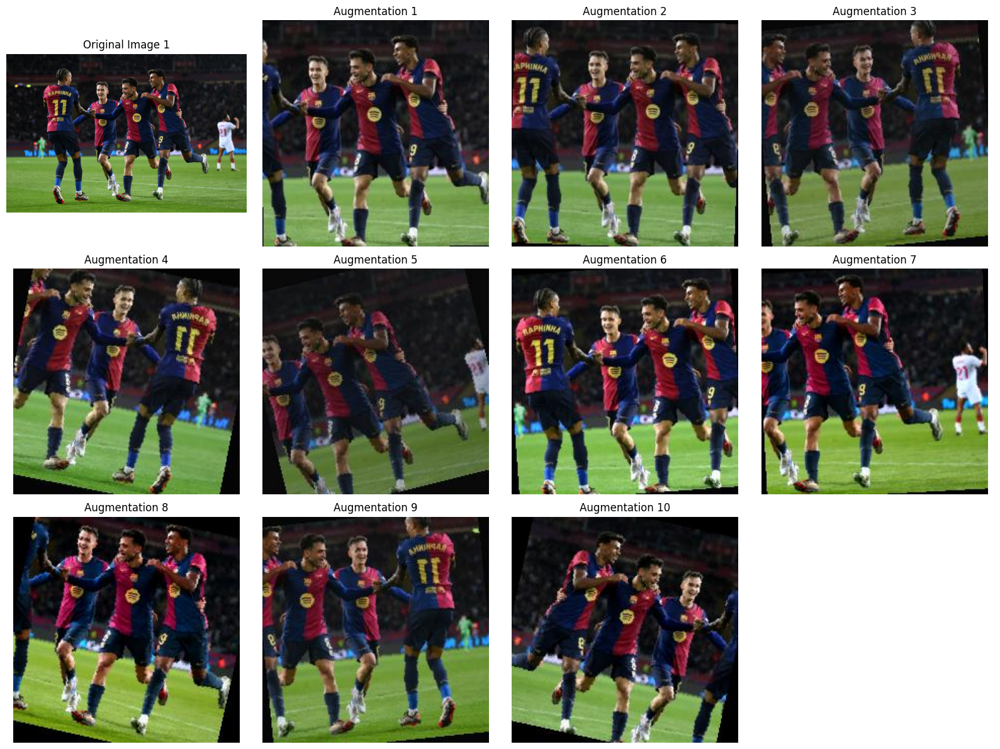

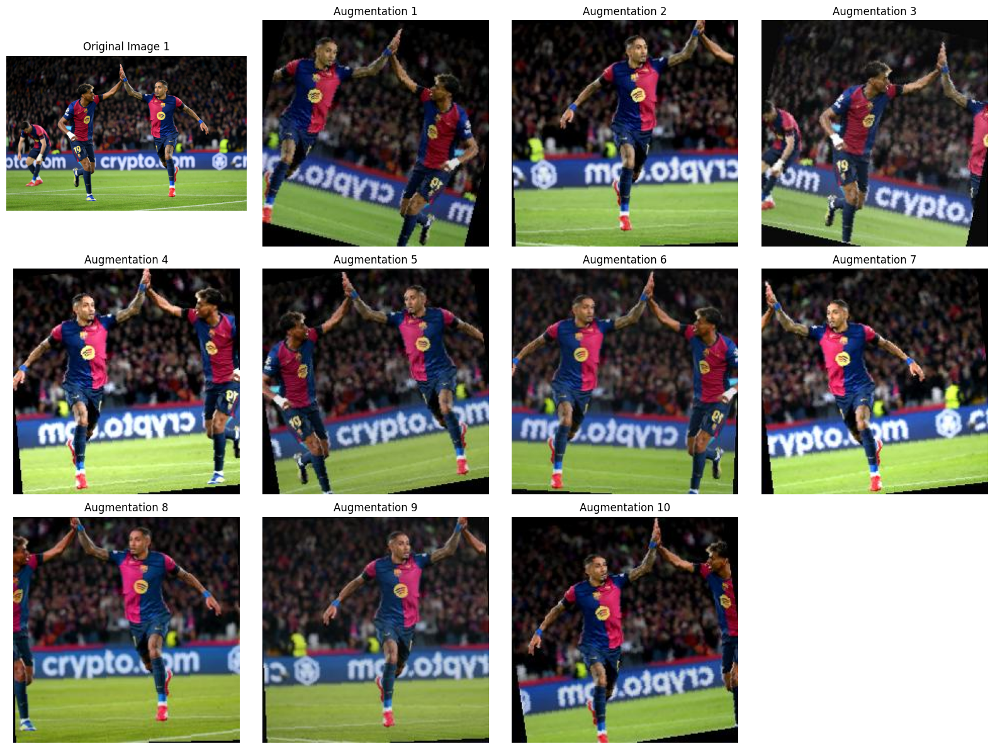

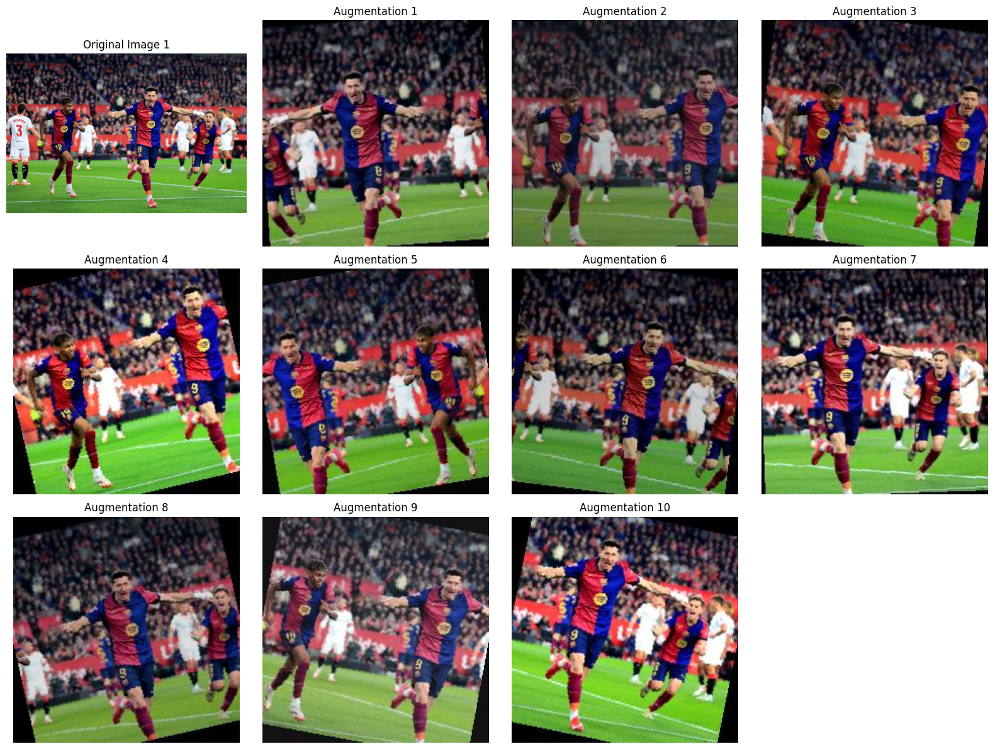

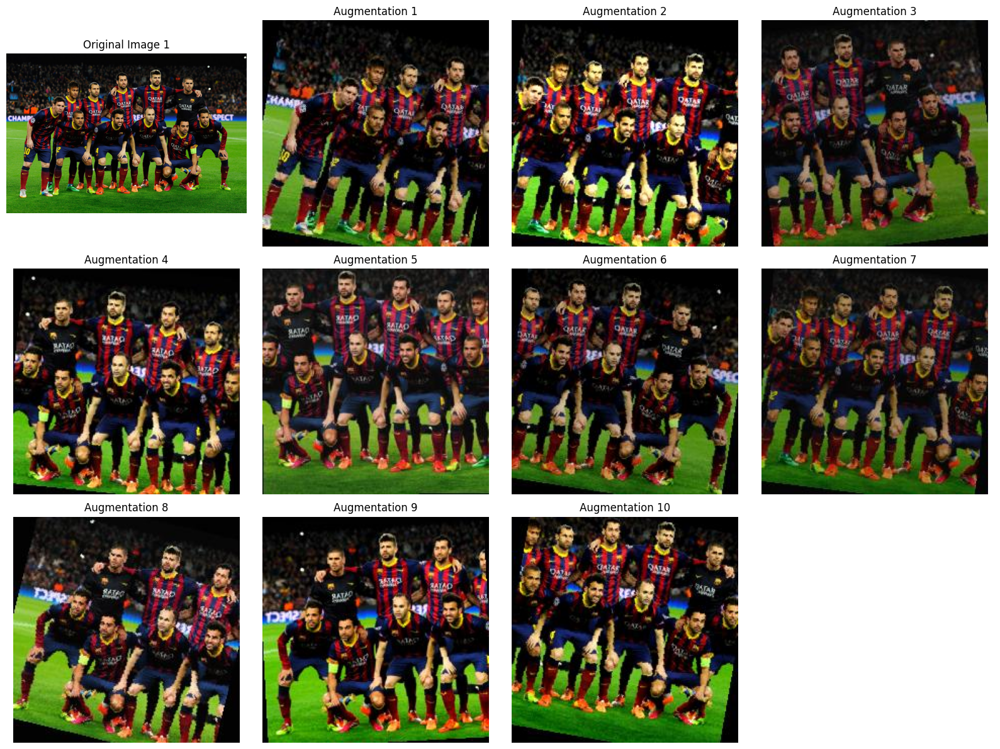

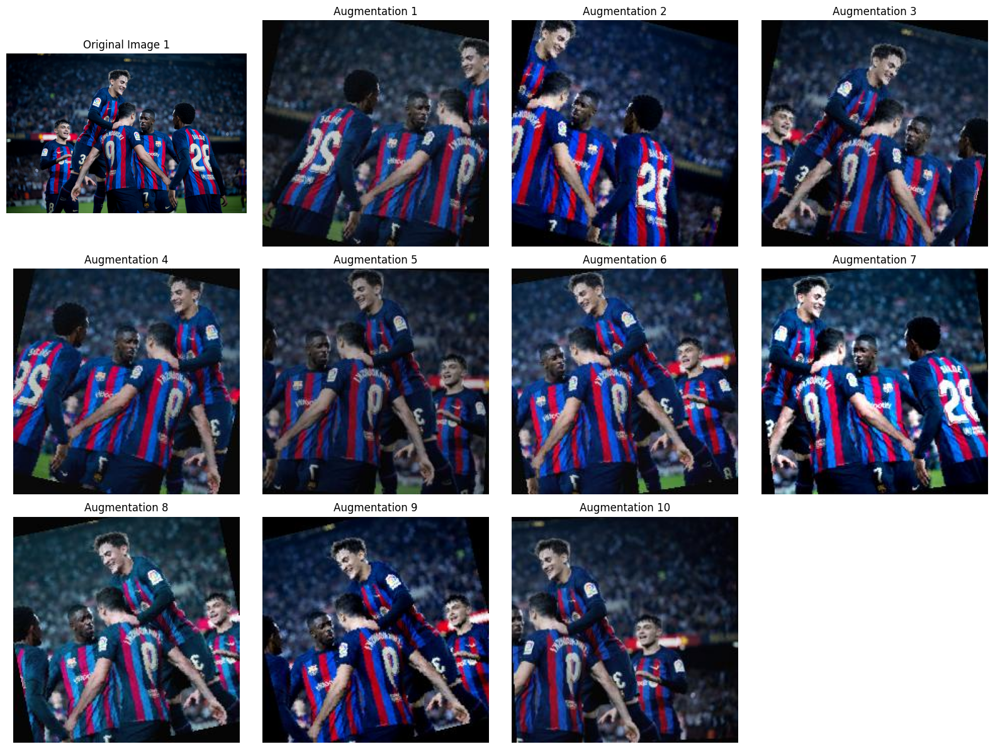

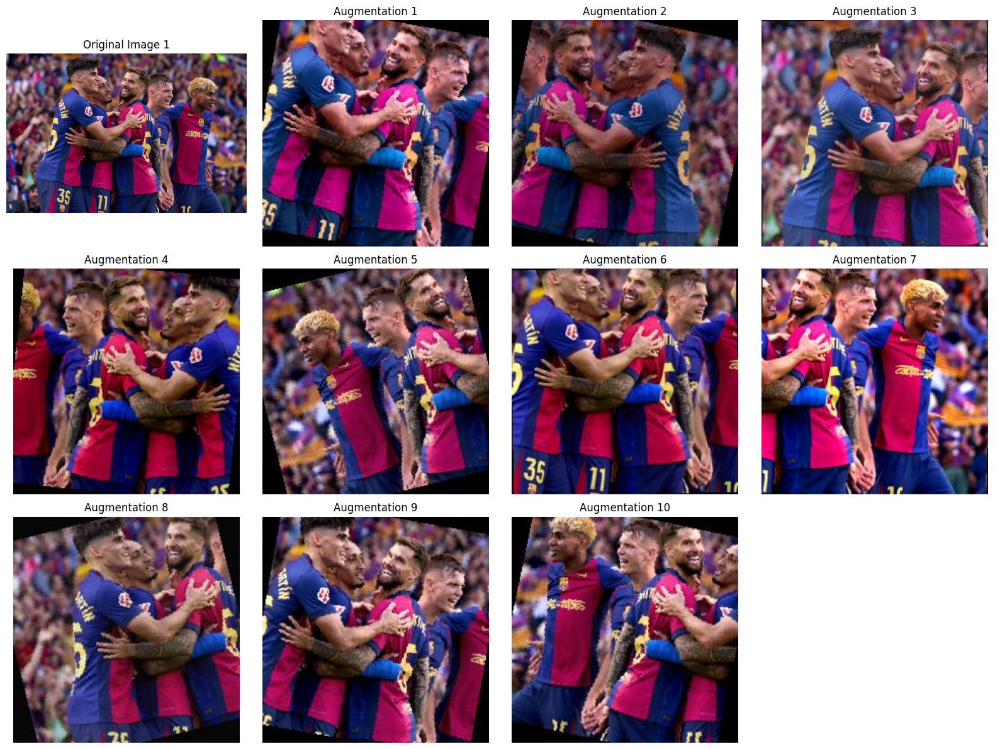

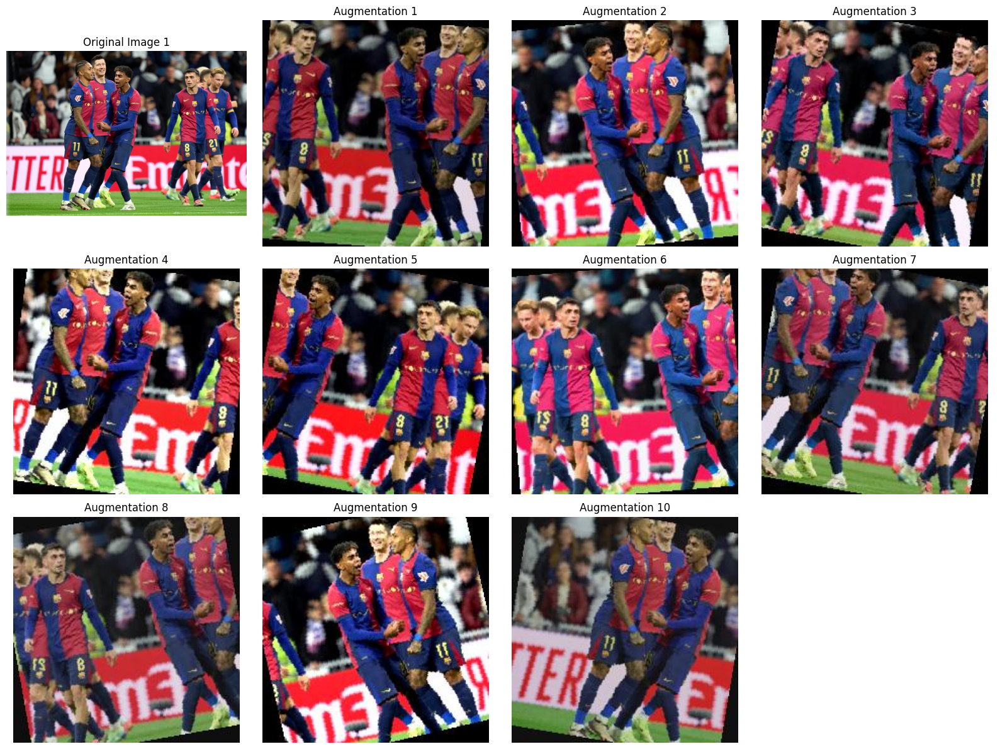

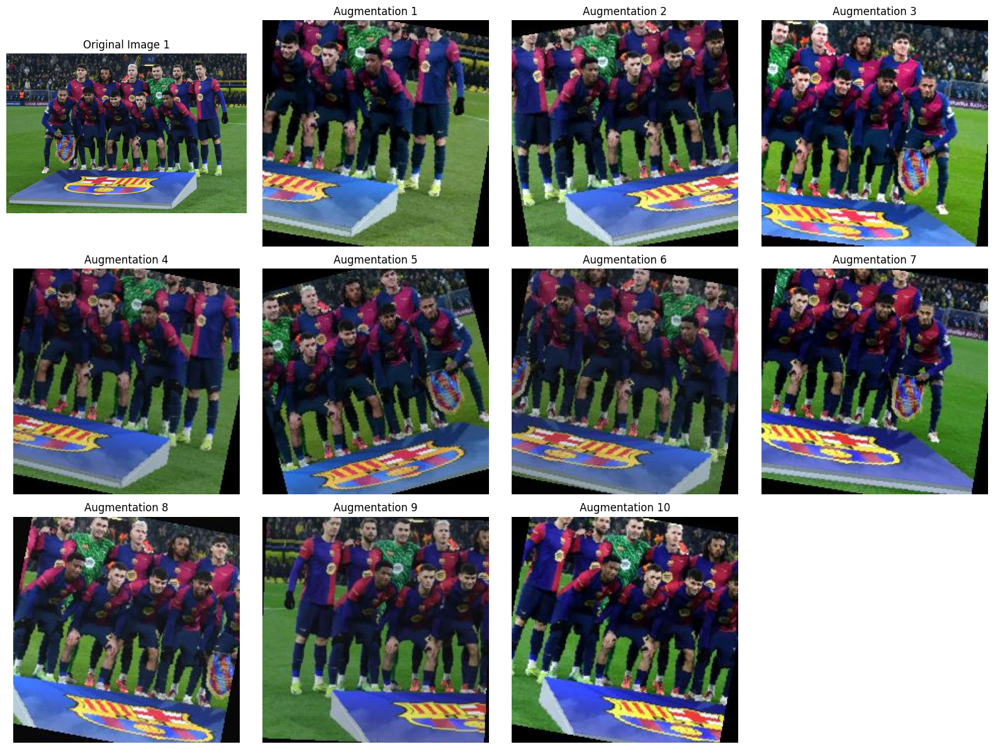

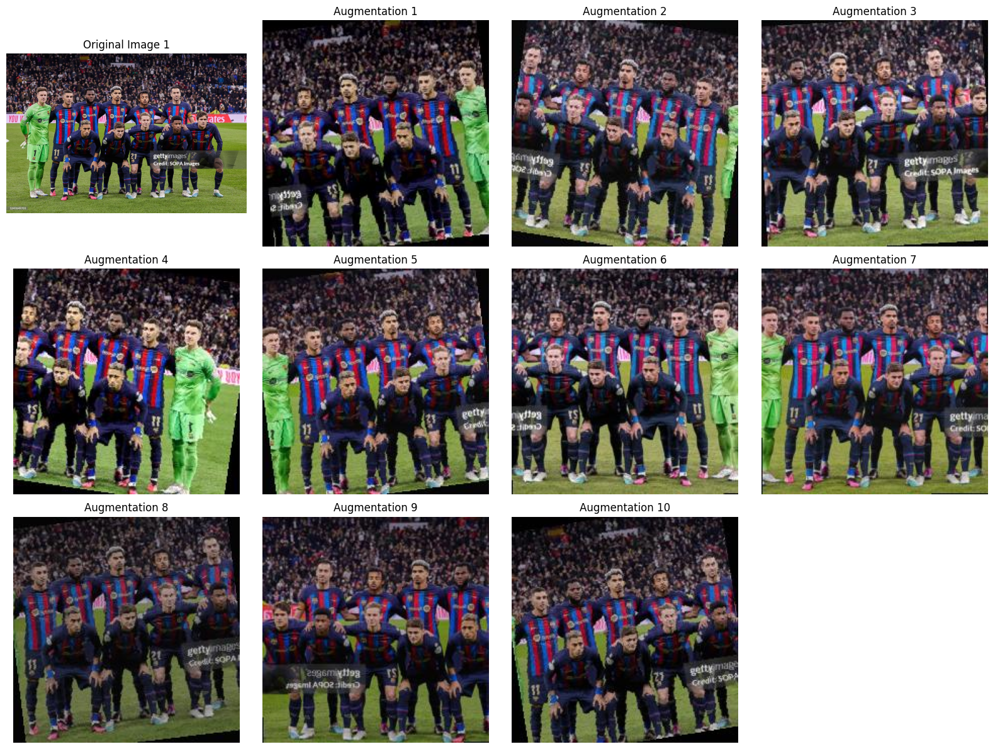

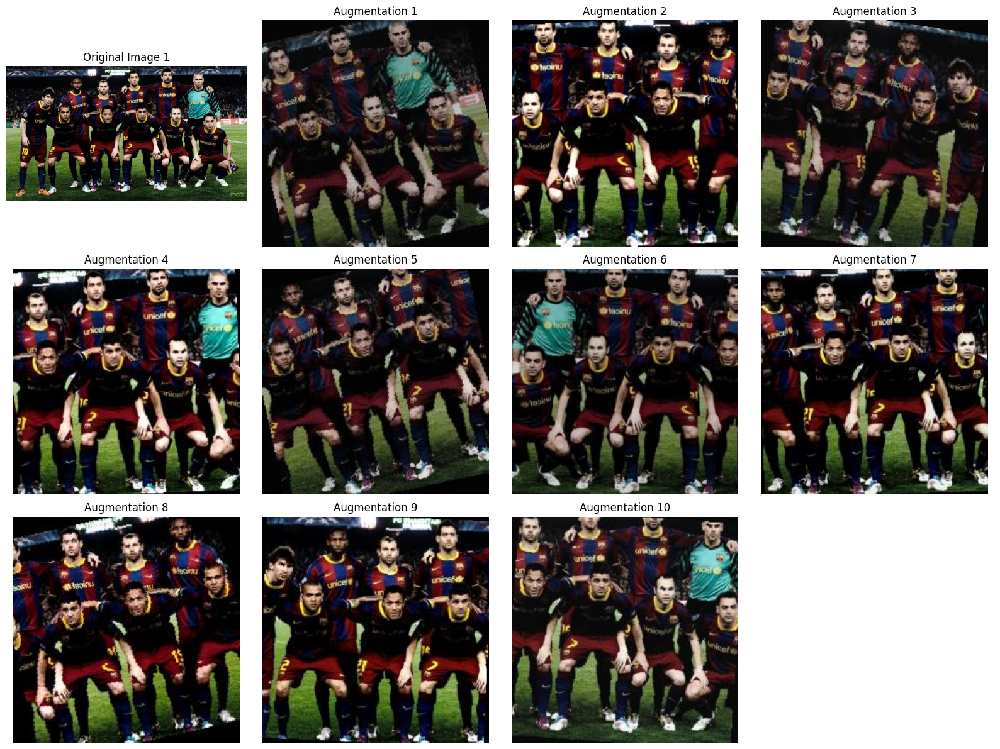

In [4]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path



for i in range(1,11):
    input_path = f"Mini Project/Raw/image {i}.jpg"
    output_dir = Path("Mini Project/Processed")
    
    original = Image.open(input_path).convert("RGB")
    
    # Create subplot grid: 3 rows × 4 columns
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    axes = axes.flatten()
    
    # Display original
    axes[0].imshow(original)
    axes[0].set_title("Original Image 1")
    axes[0].axis("off")
    
    # Display all 10 augmented images
    for j in range(1, 11):
        image_path = output_dir / f"image_{i}_aug_{j}.jpg"
        augmented = Image.open(image_path).convert("RGB")
    
        axes[j].imshow(augmented)
        axes[j].set_title(f"Augmentation {j}")
        axes[j].axis("off")
    
    # Hide the unused 12th subplot
    axes[11].axis("off")
    
    plt.tight_layout()
    plt.show()